<a href="https://colab.research.google.com/github/dairxp/Py-Colab-ALD/blob/main/22_Deep_Learning_Proyecto_MNIST_Digit_Recognizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cambiar T4 GPU

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

In [16]:
df = pd.read_csv('/content/train.csv')

In [17]:
y = df.label.values
x = df.drop("label", axis=1)

In [18]:
x = x.values
x = x / 255.0          # ← si esto no se corre, loss = nan
x = x.reshape((-1, 28, 28, 1))

In [19]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.30, random_state=103)
print("Train:", x_train.shape)
print("Test:", x_test.shape)

Train: (29400, 28, 28, 1)
Test: (12600, 28, 28, 1)


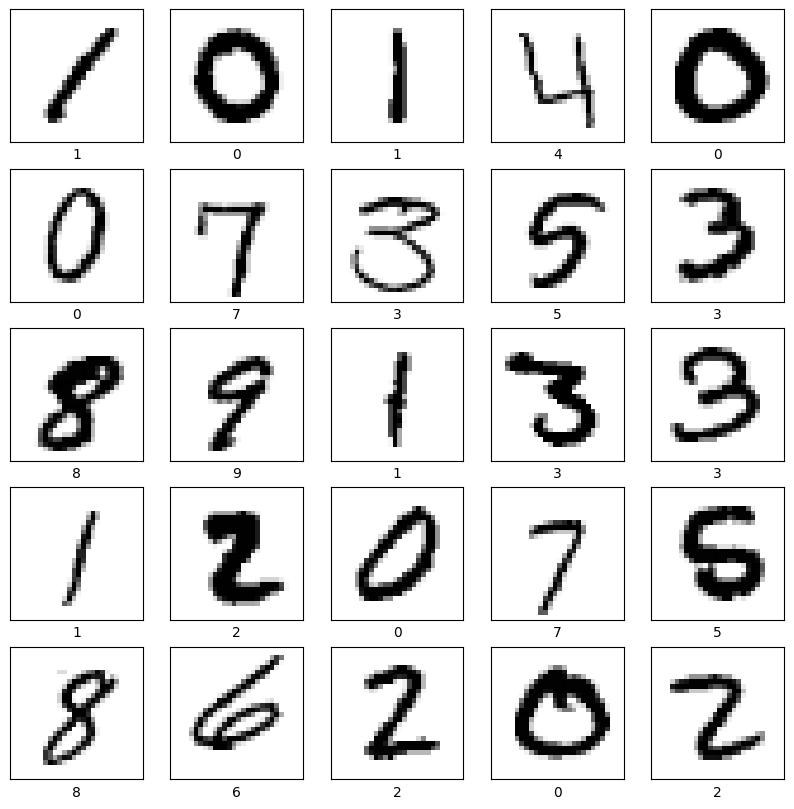

In [20]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    number = x[i].reshape(28,28)
    plt.imshow(number, cmap=plt.cm.binary)
    plt.xlabel(y[i])
plt.show()

In [21]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.30, random_state=103)

print("Train:", x_train.shape)
print("Test:", x_test.shape)

Train: (29400, 28, 28, 1)
Test: (12600, 28, 28, 1)


In [22]:
from tensorflow import keras
from tensorflow.keras import layers, models

model = models.Sequential()

# Conv2D_1 — filters aumentado de 32 a 64
model.add(layers.Conv2D(filters=64,
                        kernel_size=(5, 5),
                        activation='relu',
                        padding="same",
                        input_shape=(28, 28, 1)))

model.add(layers.MaxPooling2D(pool_size=(2, 2), strides=2))

# Conv2D_2 — filters aumentado de 64 a 128
model.add(layers.Conv2D(filters=128,
                        kernel_size=(5, 5),
                        activation='relu',
                        padding="same"))

model.add(layers.MaxPooling2D(pool_size=(2, 2), strides=2))

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 206,592 (807.00 KB)

 Trainable params: 206,592 (807.00 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dropout(rate=0.4))
model.add(layers.Dense(32, activation='relu'))
model.add(layers.Dropout(rate=0.4))
model.add(layers.Dense(10, activation='softmax'))

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       401,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 610,474 (2.33 MB)

 Trainable params: 610,474 (2.33 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train,
                    validation_data=(x_test, y_test),
                    epochs=20,        # Cambio
                    batch_size=64)

Epoch 1/20
460/460 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step - accuracy: 0.5941 - loss: 1.1577 - val_accuracy: 0.9748 - val_loss: 0.0951
Epoch 2/20
460/460 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9073 - loss: 0.3003 - val_accuracy: 0.9816 - val_loss: 0.0711
Epoch 3/20
460/460 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9410 - loss: 0.1893 - val_accuracy: 0.9865 - val_loss: 0.0493
Epoch 4/20
460/460 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9512 - loss: 0.1623 - val_accuracy: 0.9877 - val_loss: 0.0464
Epoch 5/20
460/460 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9578 - loss: 0.1363 - val_accuracy: 0.9888 - val_loss: 0.0449
Epoch 6/20
460/460 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9647 - loss: 0.1196 - val_accuracy: 0.9881 - val_loss: 0.0469
Epoch 7/20
460/460 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9674 - loss: 0.1037 - val_accuracy: 0.9888 - val_loss: 0.0483
Epoch 8/20
460/460 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9702 - loss: 0.0935 - val_accuracy: 

In [25]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print("Test accuracy:", round(test_acc * 100, 2), "%")

394/394 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9919 - loss: 0.0565
Test accuracy: 99.21 %


In [26]:
predictions = model.predict(x_test)
y_hat = np.argmax(predictions, axis=1)

errores = x_test[y_test != y_hat]
errores_count = errores.shape[0]

print("Elementos de prueba:", y_test.shape[0])
print("Errores identificados:", errores_count)
print("Porcentaje de error: {}%".format(round(errores_count * 100 / y_test.shape[0], 2)))

394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Elementos de prueba: 12600
Errores identificados: 100
Porcentaje de error: 0.79%


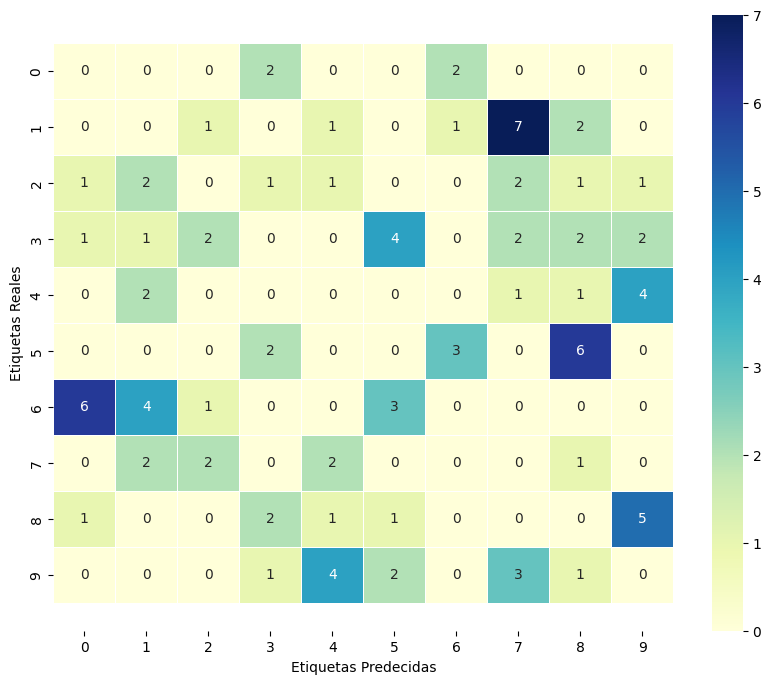

In [27]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

mod_confusion_matrix = confusion_matrix(y_test, y_hat)
for i in range(10):
    mod_confusion_matrix[i][i] = 0

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(1,1,1)
sns.heatmap(mod_confusion_matrix, linewidth=0.5, annot=True, cmap="YlGnBu")
plt.ylabel("Etiquetas Reales")
plt.xlabel("Etiquetas Predecidas")
ax.set_ylim(10.5, -0.5)
plt.show()